### Imports

In [24]:
import os
import sys
import time
import itertools
from tqdm.notebook import tqdm
import pickle
import json
import joblib
import collections

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

In [25]:
matplotlib.rcParams['figure.figsize'] = (8, 8)
sns.set_style('whitegrid')

### Задача 10


Если `catboost` не установлен, подгружаем его:

In [7]:
# !pip install catboost

In [26]:
from catboost import CatBoostClassifier # используем градиентный бустинг для классификации

#### Данные

Подгружаем файл с гугл-диска:

In [ ]:
!gdown https://drive.google.com/uc?id=1-4XarVWsldG_mkI7hX-G6ONrY24ctas6

In [27]:
df = pd.read_csv('creditcard.csv')
print(f"df: {df.shape[0]:,} x {df.shape[1]:,}")
display(df)

df: 284,807 x 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


- Данные - транзакции с отметкой о том, являются ли они мошенническими или нет

- Видим много наблюдений, с метками времени + 28 признаков + сумма транзакции + отметка фрод/не-фрод


In [28]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


- Главная проблема в таких задачах - дисбаланс классов. В данных очень много обычных переводов, и очень мало фрода, который мы как раз хотим детектировать

#### EDA

Далее громоздкий код, но он нужен, чтобы агрегировать данные для визуализации:

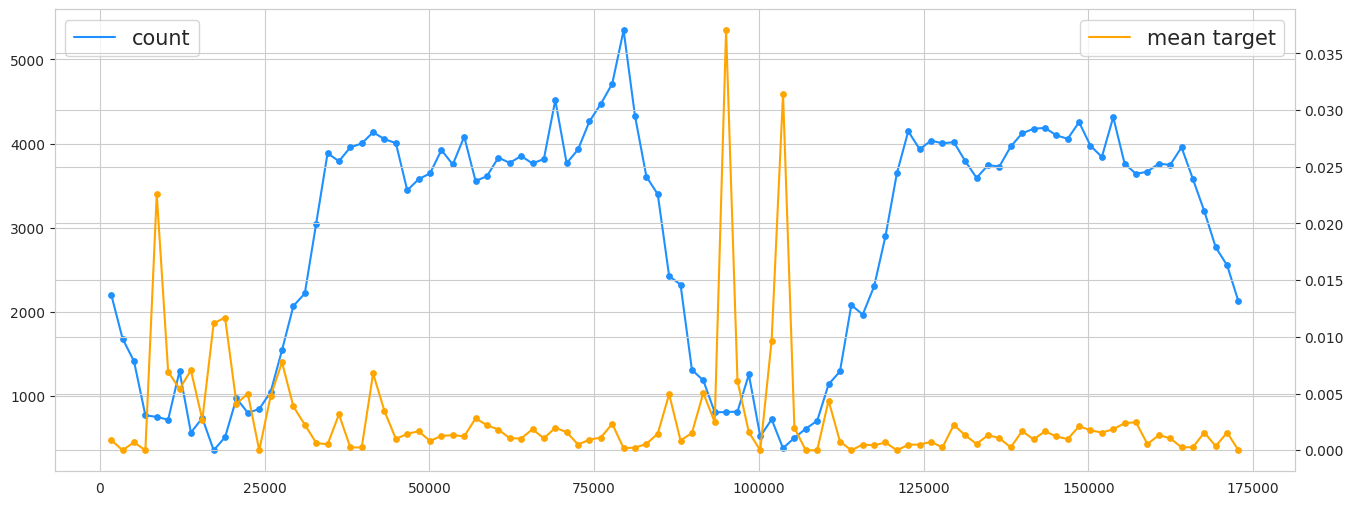

In [29]:
df['time_bins'] = pd.cut(df['Time'], bins=100).apply(lambda x: x.right).astype(float)
tmp = (
    df
    .groupby(['time_bins'])
    .agg(
        mean_target = pd.NamedAgg(column='Class', aggfunc=np.mean),
        cnt = pd.NamedAgg(column='Class', aggfunc=len)
    )
    .reset_index()
    .sort_values(by=['time_bins'], ascending=True)
)

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(
    tmp['time_bins'],
    tmp['cnt'],
    color='dodgerblue',
    label='count'
)
ax.scatter(
    tmp['time_bins'],
    tmp['cnt'],
    color='dodgerblue',
    s=15,
)
ax.legend(fontsize=15, loc='upper left');
ax2 = ax.twinx()
ax2.plot(
    tmp['time_bins'],
    tmp['mean_target'],
    color='orange',
    label='mean target'
)
ax2.scatter(
    tmp['time_bins'],
    tmp['mean_target'],
    color='orange',
    s=15
)
ax2.legend(fontsize=15, loc='upper right');

- Разбили датасет на бины по времени (агрегировали транзации за определённый период, каждая точка на графике -- кол-во транзаций за период)

- По левой оси -- кол-во транзакций, синий график
- По правой оси -- доля мошеннических переводов, жёлтый график

- Видим, что в середине есть аномальный период с низким кол-вом транзаций и высокой долей фрода
- Вырежем этот промежуток

Оставляем только часть наблюдений, удаляя аномальные периоды для простоты:

In [30]:
df = df.loc[
    (
        (df['time_bins'] >= 35_000) &
        (df['time_bins'] <= 80_000)
    ) |
    (
        (df['time_bins'] >= 122_000)
    )
].reset_index(drop=True)
print(f"df: {df.shape[0]:,} x {df.shape[1]:,}")

df: 216,278 x 32


Строим заново визуализацию:

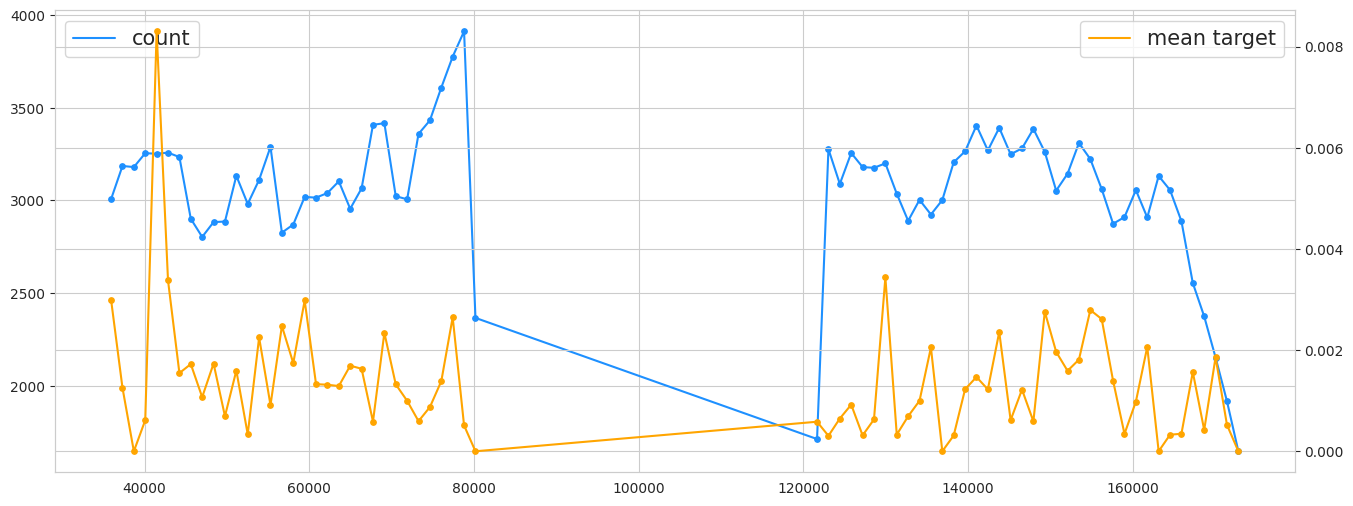

In [31]:
df['time_bins'] = pd.cut(df['Time'], bins=100).apply(lambda x: x.right).astype(float)
tmp = (
    df
    .groupby(['time_bins'])
    .agg(
        mean_target = pd.NamedAgg(column='Class', aggfunc=np.mean),
        cnt = pd.NamedAgg(column='Class', aggfunc=len)
    )
    .reset_index()
    .sort_values(by=['time_bins'], ascending=True)
)

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(
    tmp['time_bins'],
    tmp['cnt'],
    color='dodgerblue',
    label='count'
)
ax.scatter(
    tmp['time_bins'],
    tmp['cnt'],
    color='dodgerblue',
    s=15,
)
ax.legend(fontsize=15, loc='upper left');
ax2 = ax.twinx()
ax2.plot(
    tmp['time_bins'],
    tmp['mean_target'],
    color='orange',
    label='mean target'
)
ax2.scatter(
    tmp['time_bins'],
    tmp['mean_target'],
    color='orange',
    s=15
)
ax2.legend(fontsize=15, loc='upper right');

#### Разделение на обучающую, валидацию и тестовую

Теперь разделим выборку на `train`, `val` и `test`:

In [15]:
X_tr = df.loc[(df['time_bins'] <= 75_000)].reset_index(drop=True)
y_tr = X_tr['Class'].values
X_tr.drop(['Class'], axis=1, inplace=True)

X_val = df.loc[(df['time_bins'] > 75_000) & (df['time_bins'] <= 142_000)].reset_index(drop=True)
y_val = X_val['Class'].values
X_val.drop(['Class'], axis=1, inplace=True)

X_te = df.loc[(df['time_bins'] > 142_000)].reset_index(drop=True)
y_te = X_te['Class'].values
X_te.drop(['Class'], axis=1, inplace=True)

print(f"train: {X_tr.shape[0]:,} x {X_tr.shape[1]:,}")
print(f"\t0: {np.sum(y_tr == 0)} ({round(np.sum(y_tr == 0)/len(y_tr)*100, 2)}%)")
print(f"\t1: {np.sum(y_tr == 1)} ({round(np.sum(y_tr == 1)/len(y_tr)*100, 2)}%)", end='\n'*2)
print(f"val: {X_val.shape[0]:,} x {X_val.shape[1]:,}")
print(f"\t0: {np.sum(y_val == 0)} ({round(np.sum(y_val == 0)/len(y_val)*100, 2)}%)")
print(f"\t1: {np.sum(y_val == 1)} ({round(np.sum(y_val == 1)/len(y_val)*100, 2)}%)", end='\n'*2)
print(f"test: {X_te.shape[0]:,} x {X_te.shape[1]:,}")
print(f"\t0: {np.sum(y_te == 0)} ({round(np.sum(y_te == 0)/len(y_te)*100, 2)}%)")
print(f"\t1: {np.sum(y_te == 1)} ({round(np.sum(y_te == 1)/len(y_te)*100, 2)}%)", end='\n'*2)

train: 116,500 x 31
	0: 116256 (99.79%)
	1: 244 (0.21%)

val: 102,837 x 31
	0: 102676 (99.84%)
	1: 161 (0.16%)

test: 65,470 x 31
	0: 65383 (99.87%)
	1: 87 (0.13%)



- У нас суммарно всего лишь 244 + 161 + 87 мошеннических транзакций, это очень мало
- Есть риск, что модель просто "запомнит" все мошеннические примеры

Для удобства сохраним названия признаков в отдельный вектор:

In [16]:
feature_columns = np.array([
    "V1",
    "V2",
    "V3",
    "V4",
    "V5",
    "V6",
    "V7",
    "V8",
    "V9",
    "V10",
    "V11",
    "V12",
    "V13",
    "V14",
    "V15",
    "V16",
    "V17",
    "V18",
    "V19",
    "V20",
    "V21",
    "V22",
    "V23",
    "V24",
    "V25",
    "V26",
    "V27",
    "V28",
    "Amount"
])

#### LogLoss

- Задаём параметры для `catboost` в словаре, потом подаём его в `CatBoostClassifier`

- Важно, что указываем `early_stopping_rounds`, чтобы закончить обучение при выполнении критерия останова. Иначе мы бы переобучились

In [17]:
params = {
    'n_estimators': 10_000, # максимум кол-во деревьев
    'early_stopping_rounds': 200, # критерий останова: если на отложенной выборке за последние 200 итераций eval_metric не растет, то останавливаемся
    'learning_rate': 0.1,
    'objective': "Logloss", # функция потерь для бинарной классификации
    'eval_metric': 'AUC', # метрика для валидации ['AUC', 'F1', 'Recall', 'Precision']
    'boost_from_average': False, # не начинаем со среднего значения
    'task_type': "CPU",
    'verbose': 100, # логи на каждом 100-м шаге
    'random_seed': 42,

    "bootstrap_type": 'Bayesian',
    "leaf_estimation_iterations": 3,
    "leaf_estimation_method": 'Gradient',
}

logloss_model = CatBoostClassifier(**params)
logloss_model.fit(
    X_tr[feature_columns],
    y_tr,
    eval_set=[(X_val[feature_columns], y_val)]
)

0:	test: 0.9407227	best: 0.9407227 (0)	total: 91.9ms	remaining: 15m 18s
100:	test: 0.9750976	best: 0.9791358 (23)	total: 4.01s	remaining: 6m 33s
200:	test: 0.9771990	best: 0.9791358 (23)	total: 9.5s	remaining: 7m 43s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.9791358404
bestIteration = 23

Shrink model to first 24 iterations.


- Обучили самую простую модель, не думая про дисбаланс классов
- Кажется, получилось неплохо, но можно поэкспериментировать с более устойчивыми моделями

Попробуем учесть веса классов, чтобы побороться с дисбалансом:

In [32]:
class_weights = {
    0: 1.0, # обычные транзакции
    1: 100.0 # фрод (в 100 раз важнее)
}

logloss_weights_model = CatBoostClassifier(
    **params,
    class_weights=list(class_weights.values())
)

logloss_weights_model.fit(
    X_tr[feature_columns],
    y_tr,
    eval_set=[(X_val[feature_columns], y_val)]
)

0:	test: 0.9414206	best: 0.9414206 (0)	total: 205ms	remaining: 34m 12s
100:	test: 0.9778245	best: 0.9801610 (23)	total: 21.2s	remaining: 34m 39s
200:	test: 0.9794170	best: 0.9801610 (23)	total: 46.3s	remaining: 37m 36s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.9801609852
bestIteration = 23

Shrink model to first 24 iterations.


- Модель чуть дольше обучалась
- Качество сталочуть лучше
- Надеемся, что и с новыми данными будет работать устойчивее

- В `catboost` очень легко можно получить вклад каждого из признаков (feature importance)
- Обычно делается через permutational importance:
    - перемешиваем значения одного из признаков и смотрим, как изменится значение функции потерь
    - чем сильнее упадёт функция потерь после перемешивания, тем важнее признак

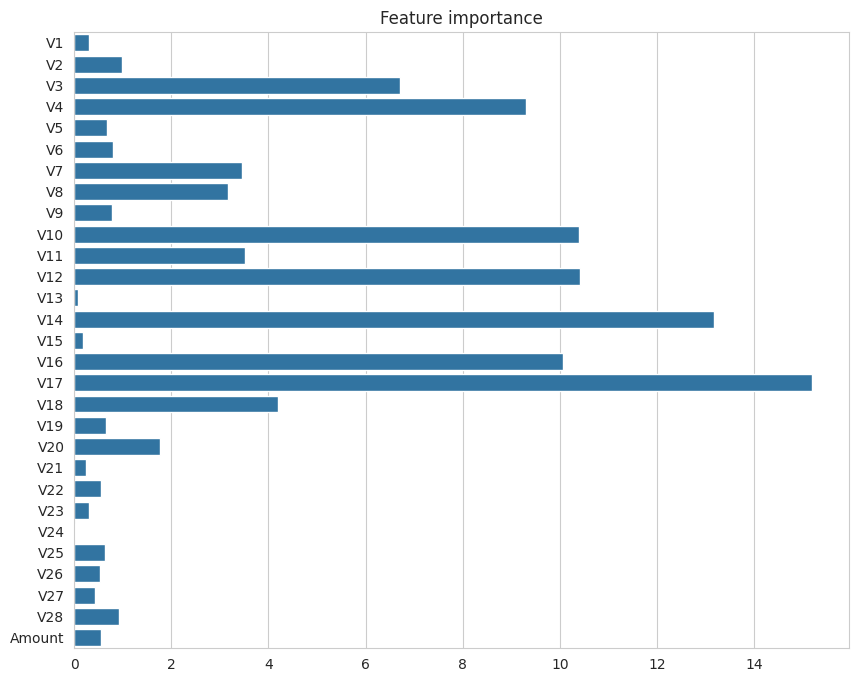

In [34]:
feature_importance = logloss_model.get_feature_importance()
plt.figure(figsize=(10, 8))
sns.barplot(x=feature_importance, y=feature_columns)
plt.title("Feature importance")
plt.show()

Можем также задавать свой собственный лосс, который будем минимизировать:

In [18]:
from scipy.special import expit

class CustomLoglossObjective(object):
    """
    L(y, z) = -y*log(sigma(z)) - (1 - y)*log(1 - sigma(z))
    """
    def calc_ders_range(self, approxes, targets, weights):
        # approxes - текущие предсказания модели (z)
        # targets - истинные метки (y)
        # weights - веса объектов
        assert len(approxes) == len(targets)
        if weights is not None:
            assert len(weights) == len(approxes)

        after_sigmoid = expit(approxes)

        antigrad = (targets - after_sigmoid) * (weights or 1)
        hess = -after_sigmoid * (1 - after_sigmoid) * (weights or 1)

        result = np.hstack((
            antigrad.reshape(-1, 1),
            hess.reshape(-1, 1)
        ))
        return result

In [19]:
params = {
    'n_estimators': 10_000,
    'early_stopping_rounds': 200,
    'learning_rate': 0.1,
    'objective': CustomLoglossObjective(),
    'eval_metric': 'AUC',
    'boost_from_average': False,
    'task_type': "CPU",
    'verbose': 100,
    'random_seed': 42,

    "bootstrap_type": 'Bayesian',
    "leaf_estimation_iterations": 3,
    "leaf_estimation_method": 'Gradient',
}

custom_logloss_model = CatBoostClassifier(**params)
custom_logloss_model.fit(
    X_tr[feature_columns],
    y_tr,
    eval_set=[(X_val[feature_columns], y_val)]
)

0:	test: 0.9407227	best: 0.9407227 (0)	total: 1.15s	remaining: 3h 12m 12s
100:	test: 0.9750976	best: 0.9791358 (23)	total: 15.3s	remaining: 24m 55s
200:	test: 0.9771990	best: 0.9791358 (23)	total: 31.2s	remaining: 25m 19s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.9791358404
bestIteration = 23

Shrink model to first 24 iterations.


- Модель с кастомным лог-лоссом получилась того же качества
- Но работает чуть дольше, так как реализация лог-лосса в `catboost` хорошо оптимизирована, и написана на C++

Можем вывести итоговые результаты по AUC на трейне, валидации и тесте:

In [20]:
from sklearn.metrics import roc_auc_score

train_predictions = custom_logloss_model.predict_proba(X_tr[feature_columns])[:, 1]
val_predictions = custom_logloss_model.predict_proba(X_val[feature_columns])[:, 1]
test_predictions = custom_logloss_model.predict_proba(X_te[feature_columns])[:, 1]

train_auc = roc_auc_score(
    y_true=y_tr,
    y_score=train_predictions
)
val_auc = roc_auc_score(
    y_true=y_val,
    y_score=val_predictions
)
test_auc = roc_auc_score(
    y_true=y_te,
    y_score=test_predictions
)

print("AUC-ROC:")
print(f"\ttrain: {round(train_auc, 4):,}")
print(f"\tval: {round(val_auc, 4):,}")
print(f"\ttest: {round(test_auc, 4):,}")

AUC-ROC:
	train: 0.9753
	val: 0.9791
	test: 0.9626


#### Focal Loss

Теперь создадим новую функцию потерь, которая изначально задумана для работы с несбалансированными датасетами:

In [40]:
import math
from scipy.special import expit

class FocalLossObjective(object):
    # боремся с дисбалансом классов
    # FL(p_t) = -alpha_t * (1 - p_t)^gamma * log(p_t)
    # alpha - параметр для балансировки классов
    # gamma - чем больше, тем выше вес сложных примеров (в нашем случае, фрод)

    def __init__(self, gamma: float=2.0, alpha: float=1.0):
        self.gamma = gamma
        self.alpha = alpha

    def calc_ders_range(self, approxes, targets, weights):
        gamma = self.gamma
        alpha = self.alpha
        assert len(approxes) == len(targets)
        if weights is not None:
            assert len(weights) == len(approxes)

#         exponents = np.exp(approxes)
#         p = exponents / (1 + exponents)
        p = expit(approxes)
        p_y = p * (targets > 0) + (1 - p) * (targets <= 0)
        a_y = alpha * (targets > 0) + (1 - alpha) * (targets <= 0)


        antigrad = (
            -(2*targets - 1)*((1-p_y)**(gamma))*(gamma * np.log(p_y) * p_y + p_y - 1)
        ) * (weights or 1)

        antihess = (
            -(2*targets - 1) * (
                 gamma * (1 - p_y)**(gamma-1) * (gamma * np.log(p_y) * p_y + p_y - 1)
                +
                 (1 - p_y)**gamma * (gamma * (1 + np.log(p_y)) + 1)
            ) * (weights or 1)
        )

        result = np.hstack((
            antigrad.reshape(-1, 1),
            antihess.reshape(-1, 1)
        ))

        return result


Также обучаем модель:

In [22]:
%%time
params = {
    'n_estimators': 10_000,
    'early_stopping_rounds': 200,
    'learning_rate': 0.1,
    'objective': FocalLossObjective(gamma=2.0),
    'eval_metric': 'AUC',
    'boost_from_average': False,
    'task_type': "CPU",
    'verbose': 100,
    'random_seed': 42,

    "bootstrap_type": 'Bayesian',
    "leaf_estimation_iterations": 3,
    "leaf_estimation_method": 'Gradient',
}

custom_flloss_model = CatBoostClassifier(**params)
custom_flloss_model.fit(
    X_tr[feature_columns],
    y_tr,
    eval_set=[(X_val[feature_columns], y_val)]
)

0:	test: 0.9414206	best: 0.9414206 (0)	total: 290ms	remaining: 48m 18s
100:	test: 0.9778245	best: 0.9801610 (23)	total: 22.2s	remaining: 36m 19s
200:	test: 0.9794170	best: 0.9801610 (23)	total: 41.9s	remaining: 34m 4s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.9801609852
bestIteration = 23

Shrink model to first 24 iterations.
CPU times: user 50.7 s, sys: 5.76 s, total: 56.4 s
Wall time: 47.8 s


- Кажется, результаты стали чуть лучше

In [23]:
from sklearn.metrics import roc_auc_score

train_predictions = custom_flloss_model.predict_proba(X_tr[feature_columns])[:, 1]
val_predictions = custom_flloss_model.predict_proba(X_val[feature_columns])[:, 1]
test_predictions = custom_flloss_model.predict_proba(X_te[feature_columns])[:, 1]

train_auc = roc_auc_score(
    y_true=y_tr,
    y_score=train_predictions
)
val_auc = roc_auc_score(
    y_true=y_val,
    y_score=val_predictions
)
test_auc = roc_auc_score(
    y_true=y_te,
    y_score=test_predictions
)

print("AUC-ROC:")
print(f"\ttrain: {round(train_auc, 4):,}")
print(f"\tval: {round(val_auc, 4):,}")
print(f"\ttest: {round(test_auc, 4):,}")

AUC-ROC:
	train: 0.9804
	val: 0.9802
	test: 0.9672
